# Solve Inverse Problems - Simulations

Let's try out the inverse module on some simulations.


## 🧪 - Experiment setup
- `fwd`: Forward solution
- `ave`: Measurements
- `ncov`: Noise covariance
- `eig`: Eigenvectors and eigenvalues of the Connectome Lacplacian.
- `gt`: Ground truth

In [1]:
# imports
import mindmap as mm
import mne

# readers
dm = mm.io.TutoManager("../../config.yml")
sr = dm.get_subject("simf10")

# data
fwd = sr.load("fwd", desc="inverse")
ave = sr.load("ave", task="rest", run="11")
ncov = sr.load("cov", task="rest", run="11")
eig = sr.load("eig")

Prepare ground truth

In [2]:
# load ground truth
ground_truth = sr.load("gt", task="rest", run="11")
eeg = sr.load("eeg", task="rest", run="11")

# extract one event
events = mne.events_from_annotations(eeg)[0]
event_time = events[1, 0] / eeg.info["sfreq"]

# crop ground truth
start = event_time - 0.449
stop = event_time + 0.449

gt = ground_truth.copy().crop(tmin=start, tmax=stop)

Used Annotations descriptions: [np.str_('1.0')]


/home/nino/Code/mindmap/mindmap/io/tutorial.py:59: RuntimeWarning: participants.tsv file not found for /home/nino/Code/mindmap/data/sub-simf10/eeg/sub-simf10_task-rest_run-11_eeg.vhdr
  subreader.add_datatype("eeg", "raw", mne_bids.BIDSPath, lambda f: mne_bids.read_raw_bids(f, verbose="warning").load_data(verbose="warning"))


## 🧬 - Data Processing
Apply inverse solver.

In [ ]:
snr = 3.0
lambda2 = 1.0 / (snr**2)

# mindmap's inverse solution
inv = mm.analysis.inverse.wCSET(
    forward = fwd,
    noise_cov = ncov,
    depth = 0.8,
    noise_norm = "sLORETA",
    eigenvectors = eig["vec"],
    eigenvalues = eig["val"],
    harm = 0.7,
)

sol = inv.solve(ave, lambda2)

# MNE-pythons' inverse solution
inv_mne = mne.minimum_norm.make_inverse_operator(
    info = ave.info,
    forward = fwd,
    noise_cov = ncov,
    fixed = True,
    depth = None,
)

stc = mne.minimum_norm.apply_inverse(
    ave,
    inv_mne,
    lambda2,
    method = "sLORETA",
)

Computing inverse operator with 203 channels.
    203 out of 203 channels remain after picking
Selected 203 channels
    Average patch normals will be employed in the rotation to the local surface coordinates....
    Converting to surface-based source orientations...
    [done]
Whitening the forward solution.
    Created an SSP operator (subspace dimension = 1)
Computing rank from covariance with rank=None
    Using tolerance 9.6e-13 (2.2e-16 eps * 203 dim * 21  max singular value)
    Estimated rank (eeg): 202
    EEG: rank 202 computed from 203 data channels with 1 projector
    Setting small EEG eigenvalues to zero (without PCA)
Creating the source covariance matrix
Adjusting source covariance matrix.
Computing SVD of whitened and weighted lead field matrix.
    largest singular value = 2.53292
    scaling factor to adjust the trace = 1.4316e+20 (nchan = 203 nzero = 1)
Preparing the inverse operator for use...
    Scaled noise and source covariance from nave = 1 to nave = 20
    Cre

## 📊 - Visualization

Measurements - timeseries

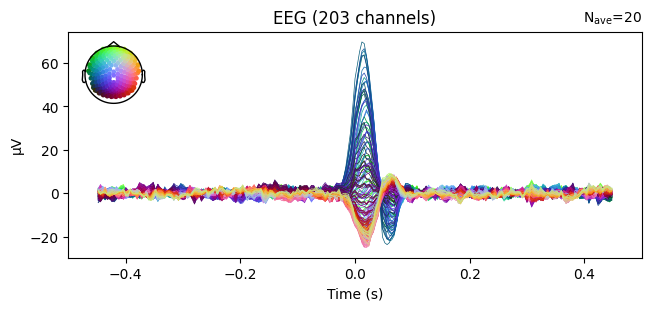

In [19]:
_ = ave.plot(xlim=(-0.5, 0.5))

Measurements - topographies

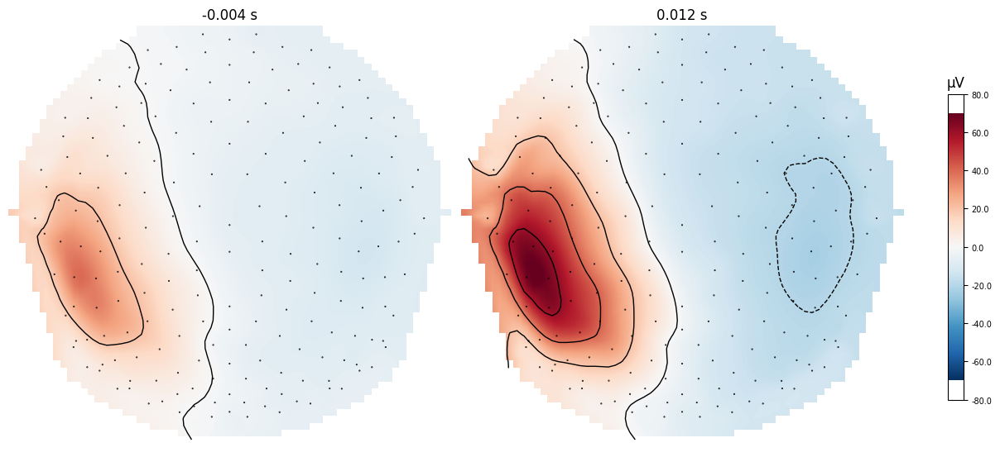

In [20]:
hrp = mm.analysis.eeg.get_rising_phase(ave, ratio=0.5)    # half rising phase
pp  = mm.analysis.eeg.get_rising_phase(ave, ratio=1)      # peak phase

_ = ave.plot_topomap(times=[hrp, pp], size=4, extrapolate="local", outlines=None)

Source reconstruction

In [24]:
mm.viz.plot_source_estimate(
    source_space = fwd["src"],
    timeseries = [sol.copy(), stc.copy(), gt.copy()],
    ts_params={"normalize":"max", "absolute":True}
).show()

Widget(value='<iframe src="http://localhost:34523/index.html?ui=P_0x72970fd8fe90_4&reconnect=auto" class="pyvi…

In [22]:
mm.viz.plot_spectrum(eig["vec"].T @ sol.data, times = sol.times).show()